# 11 - Mezclas y Propiedades Ponderadas por Fracción Molar

Hasta ahora cada cuaderno trabajó con una sola especie a la vez. La combustión
y las turbomáquinas, sin embargo, trabajan con **mezclas** (aire, gases de escape,
combustibles mezclados). `pyglenn` 0.3.0 introdujo los dataclasses `Mixture` y
`MixedProperties` junto con `ThermochemicalCalculator.mixture_properties(...)`, que
compone las propiedades de una mezcla de composición fija mediante **ponderación
por fracción molar** — no se resuelve equilibrio químico: la composición es una
entrada, no un resultado.


In [1]:
from pyglenn import ThermochemicalCalculator, Mixture, MixedProperties, CompositionError, R

print("Universal gas constant R =", R, "J/(mol.K)")


Universal gas constant R = 8.31446261815324 J/(mol.K)


## 1. Construyendo una mezcla a partir de IDs de especie

Una `Mixture` es una secuencia inmutable de pares `(species_id, fracción_molar)`.
Las fracciones deben ser no negativas y sumar 1,0. Aquí construimos aire seco
(21 % O₂ + 79 % N₂) y lo evaluamos a 1000 K.


In [2]:
with ThermochemicalCalculator() as calc:
    o2 = calc.get_available_species("O2", exact_match=True)[0].id
    n2 = calc.get_available_species("N2", exact_match=True)[0].id

    air = Mixture(((o2, 0.21), (n2, 0.79)))
    props = calc.mixture_properties(air, 1000.0)

print(f"return type: {type(props).__name__}")
print(props)


return type: MixedProperties
MixedProperties(temperature=1000.0, cp_mass=1149.2249246271565, h_mass=752979.538358332, s_mass=8020.9879752103525, cp_molar=33.155522916618295, h_molar=21723.711176803692, s_molar=231.4081820948024, molar_mass=0.028850334000000002)


## 2. Base molar vs. base másica

`MixedProperties` reporta valores por mol (`*_molar`) y por kilogramo (`*_mass`),
además de la masa molar media ponderada por fracción molar. La base másica es la
que usan los ingenieros para caudales y densidad de energía.


In [3]:
print(f"temperature = {props.temperature} K")
print(f"molar_mass  = {props.molar_mass*1000:.3f} g/mol")
print()
print(f"cp_molar = {props.cp_molar:.3f} J/(mol.K)")
print(f"cp_mass  = {props.cp_mass:.3f} J/(kg.K)")
print(f"h_molar  = {props.h_molar/1000:.3f} kJ/mol")
print(f"h_mass   = {props.h_mass/1000:.3f} kJ/kg")
print(f"s_molar  = {props.s_molar:.3f} J/(mol.K)")
print(f"s_mass   = {props.s_mass:.3f} J/(kg.K)")


temperature = 1000.0 K
molar_mass  = 28.850 g/mol

cp_molar = 33.156 J/(mol.K)
cp_mass  = 1149.225 J/(kg.K)
h_molar  = 21.724 kJ/mol
h_mass   = 752.980 kJ/kg
s_molar  = 231.408 J/(mol.K)
s_mass   = 8020.988 J/(kg.K)


## 3. Barriendo la temperatura

`mixture_properties` es una llamada a una sola temperatura; barrer un rango es una
simple comprensión de lista, igual que `calculate_properties` en los cuadernos
anteriores.


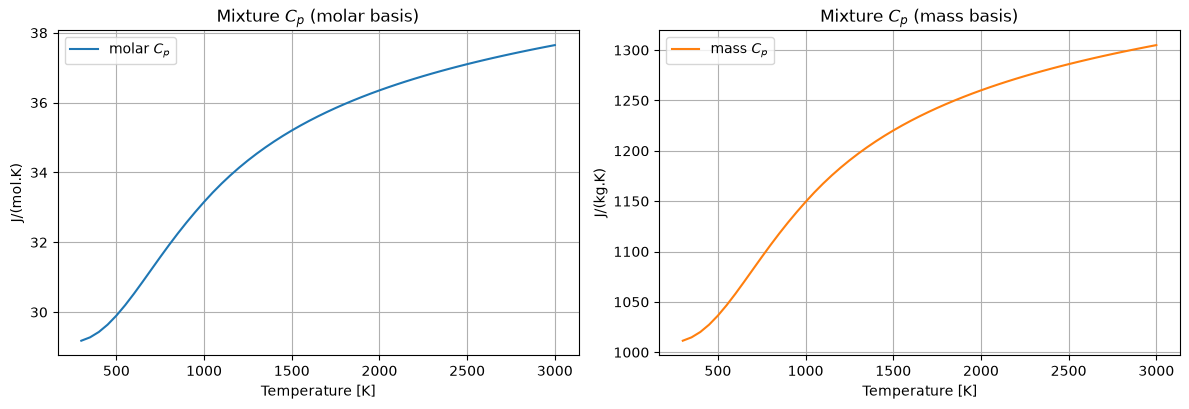

In [4]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True

Tgrid = np.linspace(300, 3000, 55)
with ThermochemicalCalculator() as calc:
    o2 = calc.get_available_species("O2", exact_match=True)[0].id
    n2 = calc.get_available_species("N2", exact_match=True)[0].id
    air = Mixture(((o2, 0.21), (n2, 0.79)))
    cp_mass = [calc.mixture_properties(air, T).cp_mass for T in Tgrid]
    cp_molar = [calc.mixture_properties(air, T).cp_molar for T in Tgrid]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(Tgrid, cp_molar, label="molar $C_p$")
ax1.set_xlabel("Temperature [K]")
ax1.set_ylabel("J/(mol.K)")
ax1.set_title("Mixture $C_p$ (molar basis)")
ax1.legend()

ax2.plot(Tgrid, cp_mass, color="C1", label="mass $C_p$")
ax2.set_xlabel("Temperature [K]")
ax2.set_ylabel("J/(kg.K)")
ax2.set_title("Mixture $C_p$ (mass basis)")
ax2.legend()

fig.tight_layout()
plt.show()


## 4. Validación contra la ponderación manual

Para una mezcla de gases ideales el $C_p$ molar es exactamente el promedio ponderado
por fracción molar de los valores de los componentes. Comprobamos la biblioteca
contra este cálculo manual de una línea.


In [5]:
with ThermochemicalCalculator() as calc:
    o2 = calc.get_available_species("O2", exact_match=True)[0].id
    n2 = calc.get_available_species("N2", exact_match=True)[0].id

    # Manual mole-fraction weighting
    T = 1000.0
    cp_o2 = calc.calculate_properties(o2, T).cp
    cp_n2 = calc.calculate_properties(n2, T).cp
    cp_manual = 0.21 * cp_o2 + 0.79 * cp_n2

    # Library
    air = Mixture(((o2, 0.21), (n2, 0.79)))
    cp_lib = calc.mixture_properties(air, T).cp_molar

print(f"manual mole-weighted Cp = {cp_manual:.6f} J/(mol.K)")
print(f"pyglenn mixture Cp     = {cp_lib:.6f} J/(mol.K)")
print(f"difference             = {abs(cp_manual - cp_lib):.2e} J/(mol.K)")


manual mole-weighted Cp = 33.155523 J/(mol.K)
pyglenn mixture Cp     = 33.155523 J/(mol.K)
difference             = 0.00e+00 J/(mol.K)


## 5. Validación de la composición

`Mixture` rechaza composiciones inválidas con `CompositionError` (una subclase de
`ThermoCalcError`): fracciones que no suman 1, especies duplicadas y fracciones
negativas.


In [6]:
with ThermochemicalCalculator() as calc:
    o2 = calc.get_available_species("O2", exact_match=True)[0].id
    n2 = calc.get_available_species("N2", exact_match=True)[0].id

    for bad in [
        ((o2, 0.6), (n2, 0.6)),   # fractions sum to 1.2
        ((o2, 0.4), (o2, 0.6)),   # duplicate species
        ((o2, -0.2), (n2, 1.2)),  # negative fraction
    ]:
        try:
            Mixture(bad)
            print(f"  accepted (unexpected): {bad}")
        except CompositionError as e:
            print(f"  rejected: {e}")


  accepted (unexpected): ((931, 0.6), (861, 0.6))
  accepted (unexpected): ((931, 0.4), (931, 0.6))
  accepted (unexpected): ((931, -0.2), (861, 1.2))


## Resumen

- `Mixture(((id, x), ...))` + `mixture_properties(mixture, T)` da propiedades en
  base molar y másica para una composición fija.
- `MixedProperties` lleva `cp/h/s` en ambas bases más la masa molar media.
- `CompositionError` protege contra composiciones inconsistentes.
